# Equivariant PDE Discovery: Kuramoto–Sivashinsky Equation

We study the **2D Kuramoto–Sivashinsky** equation on the periodic domain $[0,L]^2$:
$$f_t = -\tfrac{1}{2}|\nabla f|^2 - \Delta f - \Delta^2 f$$

The O(2)-equivariant library has 20 operators.  True coefficients: $N_4(\Delta f)\to -1$, $N_7(|\nabla f|^2)\to -0.5$, $N_{10}(\Delta^2 f)\to -1$.

In [1]:
# standard imports
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)
plt.rcParams['figure.figsize'] = (14, 4)

# add parent directory with custom library to path
import sys
sys.path.insert(0, '..')

# simulation tools (ground truth data)
from simulations import kuramoto_sivashinsky, make_regression_data

# library of PDE terms (respects the active derivative backend)
import derivatives
from library import build_equivariant_library, build_standard_library

# regression tools
from regression import TrainSTRidge

# utilities
from utils import print_pde, rotation_90


## 1. Simulate 2D KS via spectral IMEX

$$\hat{f}^{n+1} = \frac{\hat{f}^n - \frac{dt}{2}\widehat{|\nabla f|^2}}{1 - dt(|k|^2 - |k|^4)}$$

We discard the first 40% of snapshots as transient.

In [34]:
# Simulation parameters
N             = 64         # grid points per direction
L             = 32*np.pi  # domain side length
T_end         = 10.0     # end time
dt            = 0.05      # time step
save_every    = 5         # save one snapshot every 5 steps
skip_fraction = 0.4       # discard initial transient

snapshots, times = kuramoto_sivashinsky(
    N=N, L=L, T_end=T_end, dt=dt, save_every=save_every, seed=42,
)
print(f'{len(snapshots)} snapshots total, t in [{times[0]:.1f}, {times[-1]:.1f}]')
print(f'f range: [{snapshots.min():.4f}, {snapshots.max():.4f}]')


41 snapshots total, t in [0.0, 10.0]
f range: [-1.4526, 0.9207]


/tmp/ipykernel_3275648/2749190138.py:18: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


saved dynamics figure


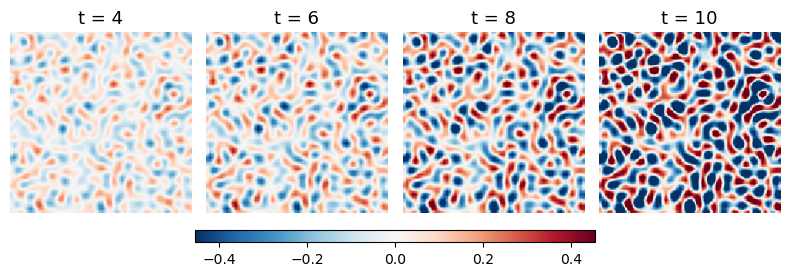

In [35]:
fig, axes = plt.subplots(1, 4, figsize=(8, 3))

skip = int(skip_fraction * len(snapshots))
snaps_use = snapshots[skip:]
times_use = times[skip:]

pidx = [0, len(snaps_use)//3, 2*len(snaps_use)//3, -1]
vabs = np.percentile(np.abs(snaps_use), 95)
for ax, idx in zip(axes, pidx):
    im = ax.imshow(snaps_use[idx], cmap='RdBu_r', vmin=-vabs, vmax=vabs,
                   origin='lower', extent=[0, L, 0, L])
    ax.set_title(f't = {times_use[idx]:.0f}', fontsize=13)
    ax.axis('off')

cbar_ax = fig.add_axes([0.25, 0.1, 0.5, 0.04])
fig.colorbar(im, cax=cbar_ax, orientation='horizontal')

plt.tight_layout()
plt.savefig('../../latex/figures/kuramoto_sivashinsky_snapshots.pdf', bbox_inches='tight')
print('saved dynamics figure')


## 2. Extract data for regression

We skip the first 40% of snapshots (transient removal) before computing $f_t$.

In [4]:
n_per_snap = 200

f_snaps, ft_snaps, idx_sets, dt_snap = make_regression_data(
    snapshots, times, n_per_snap=n_per_snap, skip_fraction=skip_fraction, seed=0,
)

Ft_all = np.concatenate([ft_snaps[s].ravel()[idx_sets[s]] for s in range(len(f_snaps))])
print(f'{len(f_snaps)} interior snapshots after transient removal, dt_snap = {dt_snap:.3f}')
print(f'Total regression points: {len(Ft_all)}')


959 interior snapshots after transient removal, dt_snap = 0.250
Total regression points: 191800


## 3. Libraries of differential terms

Both spectral and polynomial derivative backends are evaluated.

In [5]:
Theta_eq_rows_spec, Theta_std_rows_spec = [], []
Theta_eq_rows_poly, Theta_std_rows_poly = [], []

for s in range(len(f_snaps)):
    fs  = f_snaps[s]
    idx = idx_sets[s]
    with derivatives.use_backend('spectral'):
        Th_eq,  desc_eq  = build_equivariant_library(fs, L, L)
        Th_std, desc_std = build_standard_library(fs, L, L, max_order=4, max_poly=3)
    Theta_eq_rows_spec.append(Th_eq[idx])
    Theta_std_rows_spec.append(Th_std[idx])
    with derivatives.use_backend('polynomial'):
        Th_eq,  _ = build_equivariant_library(fs, L, L)
        Th_std, _ = build_standard_library(fs, L, L, max_order=4, max_poly=3)
    Theta_eq_rows_poly.append(Th_eq[idx])
    Theta_std_rows_poly.append(Th_std[idx])

Theta_eq_spec  = np.vstack(Theta_eq_rows_spec).astype(float)
Theta_std_spec = np.vstack(Theta_std_rows_spec).astype(float)
Theta_eq_poly  = np.vstack(Theta_eq_rows_poly).astype(float)
Theta_std_poly = np.vstack(Theta_std_rows_poly).astype(float)

print(f'Library shape : {Theta_eq_spec.shape}')
print(f'Condition numbers (eq / std):')
print(f'  Spectral:   {np.linalg.cond(Theta_eq_spec):.2e} / {np.linalg.cond(Theta_std_spec):.2e}')
print(f'  Polynomial: {np.linalg.cond(Theta_eq_poly):.2e} / {np.linalg.cond(Theta_std_poly):.2e}')


Library shape : (191800, 20)
Condition numbers (eq / std):
  Spectral:   2.60e+10 / 7.35e+13
  Polynomial: 2.60e+10 / 2.10e+14


## 4. Sparse regression (STRidge)

True PDE: $f_t = -\tfrac{1}{2}|\nabla f|^2 - \Delta f - \Delta^2 f$, i.e. $N_4\to -1$, $N_7\to -0.5$, $N_{10}\to -1$.

In [6]:
lam   = 1e-5
d_tol = 0.05

print('=== Ground truth PDE ===')
print('f_t = -0.5·|∇f|² - Δf - Δ²f  (N4→-1, N7→-0.5, N10→-1)\n')

print('── Spectral derivatives ──')
w_eq_spec  = TrainSTRidge(Theta_eq_spec,  Ft_all, lam, d_tol)
w_std_spec = TrainSTRidge(Theta_std_spec, Ft_all, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_spec, desc_eq)
print('Standard:');   print_pde(w_std_spec, desc_std)

print('\n── Polynomial derivatives ──')
w_eq_poly  = TrainSTRidge(Theta_eq_poly,  Ft_all, lam, d_tol)
w_std_poly = TrainSTRidge(Theta_std_poly, Ft_all, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_poly, desc_eq)
print('Standard:');   print_pde(w_std_poly, desc_std)


=== Ground truth PDE ===
f_t = -0.5·|∇f|² - Δf - Δ²f  (N4→-1, N7→-0.5, N10→-1)

── Spectral derivatives ──
Equivariant:
f_t = (-0.00539)1 + (+0.00009)f + (+0.00000)f² + (-0.99909)Δf + (+0.00001)f·Δf + (-0.47906)‖∇f‖² + (+0.00000)f²·Δf + (-1.00850)Δ²f + (+0.00165)‖∇²f‖² + (+0.02643)⟨∇Δf,∇f⟩ + (+0.00082)‖∇f‖²·Δf + (-0.01471)∇²f(∇f,∇f)
Standard:
f_t = (+0.02010)1 + (+0.75095)f_y + (-1.57973)f_x + (+0.34970)f_yy + (+0.42452)f_xy + (-0.16256)f_xx + (-0.07307)f_yyy + (-0.70335)f_xyy + (-0.40872)f_xxy + (+0.10249)f_xxx + (-0.08660)f_yyyy + (-0.50715)f_xyyy + (+1.11126)f_xxyy + (+0.60398)f_xxxy + (-0.23848)f_xxxx + (+0.00005)f + (+0.00361)f·f_y + (-0.00830)f·f_x + (+0.00173)f·f_yy + (+0.00217)f·f_xy + (-0.00065)f·f_xx + (-0.00016)f·f_yyy + (-0.00479)f·f_xyy + (-0.00276)f·f_xxy + (+0.00038)f·f_xxx + (-0.00049)f·f_yyyy + (-0.00219)f·f_xyyy + (+0.00525)f·f_xxyy + (+0.00265)f·f_xxxy + (-0.00114)f·f_xxxx + (+0.00000)f^2 + (+0.00001)f^2·f_y + (-0.00001)f^2·f_x + (+0.00000)f^2·f_yy + (+0.00000)f^2·f_

In [7]:
# True coefficients: N4(Δf)→-1, N7(|∇f|²)→-0.5, N10(Δ²f)→-1
true_eq = np.zeros(len(desc_eq))
true_eq[4]  = -1.0
true_eq[7]  = -0.5
true_eq[10] = -1.0
act = np.abs(true_eq) > 1e-10

print('--- Recovery summary (clean data) ---')
print('True: N4(Δf)→-1, N7(|∇f|²)→-0.5, N10(Δ²f)→-1\n')

for tag, w in [('Spectral  eq', w_eq_spec), ('Polynomial eq', w_eq_poly)]:
    nz  = np.count_nonzero(np.abs(w) > 1e-10)
    fp  = int(np.sum((np.abs(w) > 1e-10) & ~act))
    fn  = int(np.sum((np.abs(w) < 1e-10) &  act))
    err = float(np.max(np.abs(w[act] - true_eq[act])))
    print(f'  {tag}: {nz} active, fp={fp}, fn={fn}, max_coeff_err={err:.3e}')

for tag, w in [('Spectral  std', w_std_spec), ('Polynomial std', w_std_poly)]:
    nz = np.count_nonzero(np.abs(w) > 1e-10)
    print(f'  {tag}: {nz} active terms out of {len(w)}')


--- Recovery summary (clean data) ---
True: N4(Δf)→-1, N7(|∇f|²)→-0.5, N10(Δ²f)→-1

  Spectral  eq: 12 active, fp=10, fn=1, max_coeff_err=1.000e+00
  Polynomial eq: 18 active, fp=15, fn=0, max_coeff_err=1.000e+00
  Spectral  std: 58 active terms out of 60
  Polynomial std: 59 active terms out of 60


## 5. Robustness to noise

We add 2% Gaussian observation noise and repeat the discovery.

In [8]:
noise_level = 0.02   # 2% of clean snapshot std

snapshots_noisy, _ = kuramoto_sivashinsky(
    N=N, L=L, T_end=T_end, dt=dt, save_every=save_every, seed=42,
    obs_noise=noise_level,
)

f_snaps_n, ft_snaps_n, idx_sets_n, _ = make_regression_data(
    snapshots_noisy, times, n_per_snap=n_per_snap, skip_fraction=skip_fraction, seed=0,
)
Ft_n = np.concatenate([ft_snaps_n[s].ravel()[idx_sets_n[s]] for s in range(len(f_snaps_n))])

Theta_eq_n_rows_spec, Theta_std_n_rows_spec = [], []
Theta_eq_n_rows_poly, Theta_std_n_rows_poly = [], []

for s in range(len(f_snaps_n)):
    idx = idx_sets_n[s]
    with derivatives.use_backend('spectral'):
        Th_eq, _  = build_equivariant_library(f_snaps_n[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_n[s], L, L, max_order=4, max_poly=3)
    Theta_eq_n_rows_spec.append(Th_eq[idx])
    Theta_std_n_rows_spec.append(Th_std[idx])
    with derivatives.use_backend('polynomial'):
        Th_eq, _  = build_equivariant_library(f_snaps_n[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_n[s], L, L, max_order=4, max_poly=3)
    Theta_eq_n_rows_poly.append(Th_eq[idx])
    Theta_std_n_rows_poly.append(Th_std[idx])

Theta_eq_n_spec  = np.vstack(Theta_eq_n_rows_spec).astype(float)
Theta_std_n_spec = np.vstack(Theta_std_n_rows_spec).astype(float)
Theta_eq_n_poly  = np.vstack(Theta_eq_n_rows_poly).astype(float)
Theta_std_n_poly = np.vstack(Theta_std_n_rows_poly).astype(float)
print(f'Noisy: {len(Ft_n)} regression points, noise={noise_level*100:.0f}%')


Noisy: 191800 regression points, noise=2%


In [9]:
print(f'── Spectral (obs_noise = {noise_level*100:.0f}%) ──')
w_eq_n_spec  = TrainSTRidge(Theta_eq_n_spec,  Ft_n, lam, d_tol)
w_std_n_spec = TrainSTRidge(Theta_std_n_spec, Ft_n, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_n_spec, desc_eq)
print('Standard:');   print_pde(w_std_n_spec, desc_std)

print(f'\n── Polynomial (obs_noise = {noise_level*100:.0f}%) ──')
w_eq_n_poly  = TrainSTRidge(Theta_eq_n_poly,  Ft_n, lam, d_tol)
w_std_n_poly = TrainSTRidge(Theta_std_n_poly, Ft_n, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_n_poly, desc_eq)
print('Standard:');   print_pde(w_std_n_poly, desc_std)

print('\n--- Noisy recovery summary ---')
for tag, w in [('Spectral  eq', w_eq_n_spec), ('Polynomial eq', w_eq_n_poly)]:
    fp  = int(np.sum((np.abs(w) > 1e-10) & ~act))
    fn  = int(np.sum((np.abs(w) < 1e-10) &  act))
    err = float(np.max(np.abs(w[act] - true_eq[act])))
    print(f'  {tag}: fp={fp}, fn={fn}, max_coeff_err={err:.3e}')


── Spectral (obs_noise = 2%) ──
Equivariant:
f_t = (-1.27763)1 + (+0.00824)f + (+0.00001)f² + (+0.00000)f³ + (-0.02279)Δf + (-0.00004)f·Δf + (-0.00187)‖∇f‖² + (-0.00000)f²·Δf + (-0.00000)f·‖∇f‖² + (-0.00090)Δ²f + (-0.00000)f·Δ²f + (-0.00001)Δf·Δf + (+0.00002)‖∇²f‖² + (-0.00018)⟨∇Δf,∇f⟩ + (+0.00000)f²·Δ²f + (-0.00000)f·Δf·Δf + (+0.00000)f·‖∇²f‖² + (-0.00000)f·⟨∇Δf,∇f⟩ + (-0.00000)‖∇f‖²·Δf + (-0.00000)∇²f(∇f,∇f)
Standard:
f_t = (+0.01503)1 + (+0.19411)f_y + (-0.04562)f_x + (+0.10197)f_yy + (-0.10485)f_xy + (+0.00953)f_xx + (+0.00926)f_yyy + (+0.04345)f_xyy + (+0.06985)f_xxy + (-0.01583)f_xxx + (+0.01497)f_yyyy + (+0.00234)f_xyyy + (-0.00375)f_xxyy + (-0.01421)f_xxxy + (+0.00106)f_xxxx + (+0.00003)f + (+0.00071)f·f_y + (+0.00003)f·f_x + (+0.00060)f·f_yy + (-0.00076)f·f_xy + (+0.00006)f·f_xx + (+0.00001)f·f_yyy + (+0.00023)f·f_xyy + (+0.00036)f·f_xxy + (-0.00006)f·f_xxx + (+0.00007)f·f_yyyy + (-0.00001)f·f_xyyy + (-0.00001)f·f_xxyy + (-0.00007)f·f_xxxy + (+0.00000)f·f_xxxx + (+0.00000)f^2 

## 6. Equivariance test

We rotate the data by 90° and repeat the regression.

In [10]:
# Rotate all snapshots 90° and re-run the same pipeline
snaps_r = rotation_90(snapshots.transpose(1, 2, 0)).transpose(2, 0, 1)

f_snaps_r, ft_snaps_r, idx_sets_r, _ = make_regression_data(
    snaps_r, times, n_per_snap=n_per_snap, skip_fraction=skip_fraction, seed=0,
)
Ft_r = np.concatenate([ft_snaps_r[s].ravel()[idx_sets_r[s]] for s in range(len(f_snaps_r))])

Theta_eq_r_rows_spec, Theta_std_r_rows_spec = [], []
Theta_eq_r_rows_poly, Theta_std_r_rows_poly = [], []

for s in range(len(f_snaps_r)):
    idx = idx_sets_r[s]
    with derivatives.use_backend('spectral'):
        Th_eq, _  = build_equivariant_library(f_snaps_r[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_r[s], L, L, max_order=4, max_poly=3)
    Theta_eq_r_rows_spec.append(Th_eq[idx])
    Theta_std_r_rows_spec.append(Th_std[idx])
    with derivatives.use_backend('polynomial'):
        Th_eq, _  = build_equivariant_library(f_snaps_r[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_r[s], L, L, max_order=4, max_poly=3)
    Theta_eq_r_rows_poly.append(Th_eq[idx])
    Theta_std_r_rows_poly.append(Th_std[idx])

Theta_eq_r_spec  = np.vstack(Theta_eq_r_rows_spec).astype(float)
Theta_std_r_spec = np.vstack(Theta_std_r_rows_spec).astype(float)
Theta_eq_r_poly  = np.vstack(Theta_eq_r_rows_poly).astype(float)
Theta_std_r_poly = np.vstack(Theta_std_r_rows_poly).astype(float)

print('── Spectral (rotated clean) ──')
w_eq_r_spec  = TrainSTRidge(Theta_eq_r_spec,  Ft_r, lam, d_tol)
w_std_r_spec = TrainSTRidge(Theta_std_r_spec, Ft_r, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_r_spec, desc_eq)
print('Standard:');   print_pde(w_std_r_spec, desc_std)

print('\n── Polynomial (rotated clean) ──')
w_eq_r_poly  = TrainSTRidge(Theta_eq_r_poly,  Ft_r, lam, d_tol)
w_std_r_poly = TrainSTRidge(Theta_std_r_poly, Ft_r, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_r_poly, desc_eq)
print('Standard:');   print_pde(w_std_r_poly, desc_std)


── Spectral (rotated clean) ──
Equivariant:
f_t = (-0.01265)1 + (+0.00006)f + (+0.00000)f² + (-0.99124)Δf + (+0.00002)f·Δf + (-0.47977)‖∇f‖² + (+0.00000)f²·Δf + (-1.00133)Δ²f + (+0.00002)f·Δ²f + (+0.00160)‖∇²f‖² + (+0.02465)⟨∇Δf,∇f⟩ + (+0.00000)f²·Δ²f + (-0.00000)f·⟨∇Δf,∇f⟩ + (+0.00085)‖∇f‖²·Δf + (-0.01457)∇²f(∇f,∇f)
Standard:
f_t = (+0.02008)1 + (-2.15729)f_y + (-1.04107)f_x + (+0.09732)f_yy + (+0.36621)f_xy + (+0.53960)f_xx + (-0.48434)f_yyy + (+0.29724)f_xyy + (-1.22647)f_xxy + (+0.02783)f_xxx + (-0.24850)f_yyyy + (-0.70741)f_xyyy + (+0.60314)f_xxyy + (+1.10391)f_xxxy + (-0.03836)f_xxxx + (+0.00005)f + (-0.01122)f·f_y + (-0.00506)f·f_x + (+0.00025)f·f_yy + (+0.00178)f·f_xy + (+0.00273)f·f_xx + (-0.00243)f·f_yyy + (+0.00244)f·f_xyy + (-0.00751)f·f_xxy + (+0.00002)f·f_xxx + (-0.00133)f·f_yyyy + (-0.00372)f·f_xyyy + (+0.00282)f·f_xxyy + (+0.00586)f·f_xxxy + (+0.00000)f^2 + (-0.00002)f^2·f_y + (-0.00001)f^2·f_x + (+0.00000)f^2·f_yy + (+0.00000)f^2·f_xy + (+0.00000)f^2·f_xx + (-0.00000)f

In [11]:
print('Coefficient change under 90° rotation (clean data):')
for tag, w, wr in [
    ('Spectral  eq',  w_eq_spec,  w_eq_r_spec),
    ('Polynomial eq', w_eq_poly,  w_eq_r_poly),
    ('Spectral  std', w_std_spec, w_std_r_spec),
    ('Polynomial std',w_std_poly, w_std_r_poly),
]:
    print(f'  {tag}: max|Δc| = {np.max(np.abs(w - wr)):.2e}')


Coefficient change under 90° rotation (clean data):
  Spectral  eq: max|Δc| = 7.85e-03
  Polynomial eq: max|Δc| = 1.64e-02
  Spectral  std: max|Δc| = 2.91e+00
  Polynomial std: max|Δc| = 3.55e+00
